# 6 · The compute budget

Every training run wrote one row to `validation/results/compute_budget.csv`: its error,
training time per optimiser stage and steps to converge. This notebook summarises it per phase.
Column definitions: [validation/results/README.md](../validation/results/README.md). See
[Lesson 6](../docs/lessons/06-verification-validation-and-when-to-use-a-pinn.md).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

from pinncfd import io, plotting as P

torch.set_num_threads(1)  # one thread: reductions in a fixed order, reproducible outputs
P.use_style()
DEG = np.pi / 180
ROOT = Path("..").resolve()
RESULTS = ROOT / "validation" / "results"
CK = RESULTS / "checkpoints"
DEVICE = "cpu"

In [2]:
rows = [r for r in io.read_budget() if r["adam_steps"]]  # training runs only
groups = {}
for r in rows:  # the 40 search genomes form one group
    case = "search (proxy)" if r["case"].startswith("search_") else r["case"]
    groups.setdefault((r["phase"], case), []).append(r)

def steps(r, target):  # None: target not recorded for this phase; -1: never reached
    return json.loads(r["metrics_json"]).get(f"steps_to_{target:.0e}")

print("mean error and training time; median steps to the target over the runs that reached it")
print(f"{'phase':7s} {'case':22s} {'runs':>4s} {'error':>9s} {'time [s]':>9s} {'to 3e-2':>8s} {'to 1e-2':>8s}")
for (phase, case), rs in sorted(groups.items()):
    e = np.mean([float(r["error"]) for r in rs])
    t = np.mean([float(r["time_total_s"]) for r in rs])
    s3 = [steps(r, 3e-2) for r in rs]
    s2 = [steps(r, 1e-2) for r in rs]
    fmt = lambda s: "—" if None in s else "never" if max(s) < 0 else f"{int(np.median([x for x in s if x >= 0]))}"
    print(f"{phase:7s} {case:22s} {len(rs):4d} {e:9.2e} {t:9.0f} {fmt(s3):>8s} {fmt(s2):>8s}")

mean error and training time; median steps to the target over the runs that reached it
phase   case                   runs     error  time [s]  to 3e-2  to 1e-2
phase1  phi_soft                  3  1.93e-04       177        —     4700
phase1  psi_hard                  3  7.68e-05       183        —      500
phase1  psi_hard_lifting          3  6.65e-05       194        —      300
phase1  psi_soft                  3  1.19e-03       168        —     5700
phase2  data_only                 1  6.19e-03        89      750     4250
phase2  physics_data              3  1.17e-02       575     4250     5000
phase2  physics_only              1  2.04e-02       464     4750    never
phase2  plain_features            1  2.53e-02       361     4750    never
phase3  champion                  3  7.15e-03       653     2500     4500
phase3  search (proxy)           40  1.01e-01        60      500    never
phase5  ringleb                   2  1.43e-03       421      650     3450
phase5  wedge_plain      

phase1: 36.1 min over 12 runs
phase2: 44.0 min over 6 runs
phase3: 72.7 min over 43 runs
phase5: 53.4 min over 5 runs


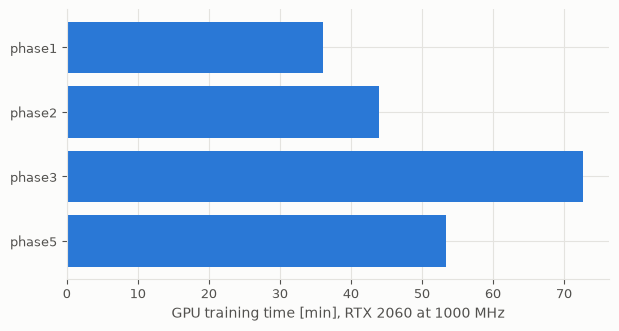

In [3]:
per_phase = {}
for r in rows:
    per_phase[r["phase"]] = per_phase.get(r["phase"], 0.0) + float(r["time_total_s"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(list(per_phase), [v / 60 for v in per_phase.values()], color=P.SERIES[0])
ax.set_xlabel("GPU training time [min], RTX 2060 at 1000 MHz"); ax.invert_yaxis()
for k, v in per_phase.items():
    print(f"{k}: {v / 60:.1f} min over {sum(r['phase'] == k for r in rows)} runs")